# 2 · IEG score vs intrinsic physiology within cell type

One ephys feature regressed on the IEG score with transcriptomic type as a fixed effect and standard errors
clustered by mouse, followed by the harmonised M1 -> V1 set-test table. Needs the M1 Patch-seq files and
`m1_patchseq_ephys_features.csv` (`uv run python data/fetch_data.py`).

In [1]:
import sys, pathlib
HERE = pathlib.Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "analysis" / "common").exists())
sys.path.insert(0, str(ROOT / "analysis" / "common"))
import numpy as np, pandas as pd, scanpy as sc, anndata as ad, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from common import PATCHSEQ_DIR, EPHYS_CSV, GENE_SETS, VALIDATION_TABLES
sc.settings.verbosity = 0
exon = pd.read_csv(PATCHSEQ_DIR / "GSE163764_m1_patchseq_exon_counts.csv", index_col=0)
intron = pd.read_csv(PATCHSEQ_DIR / "GSE163764_m1_patchseq_intron_counts.csv", index_col=0).reindex_like(exon).fillna(0)
meta = pd.read_csv(PATCHSEQ_DIR / "m1_patchseq_meta_data.csv", sep="\t").set_index("Cell")
counts = (exon + intron).T
cells = counts.index.intersection(meta.index)
a = ad.AnnData(counts.loc[cells].values.astype(np.float32), obs=meta.loc[cells].copy(), var=pd.DataFrame(index=counts.columns))
a.obs["n_genes"] = (a.X > 0).sum(1)
a = a[((a.obs["RNA family"] != "low quality") & a.obs["Exclusion reasons"].isna() & (a.obs["n_genes"] >= 1000)).values].copy()
sc.pp.normalize_total(a, target_sum=1e6); sc.pp.log1p(a)
sc.tl.score_genes(a, GENE_SETS["IEG_rapid"], score_name="ieg_score", ctrl_size=100, n_bins=25, random_state=0)
ephys = pd.read_csv(EPHYS_CSV).set_index("cell id")
df = a.obs[["RNA type", "Mouse", "n_genes", "ieg_score"]].join(ephys, how="inner")
df = df.rename(columns={"RNA type": "ttype", "Mouse": "mouse"}); df["ttype"] = df["ttype"].astype(str)
print(len(df), "cells with expression and ephys")

1226 cells with expression and ephys


## Within-type model for rheobase in L5 excitatory cells

n = 126 cells, 54 mice
beta = -0.24 SD per SD of IEG score (95% CI -0.43 to -0.04), p = 0.016


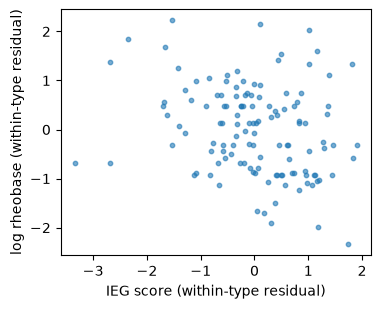

In [2]:
l5 = df[df["ttype"].str.match(r"L5 (IT|ET)_")].dropna(subset=["Rheobase (pA)"]).copy()
z = lambda v: (v - v.mean()) / v.std()
l5["y"] = z(np.log(l5["Rheobase (pA)"])); l5["s"] = z(l5["ieg_score"]); l5["lg"] = np.log(l5["n_genes"])
fit = smf.ols("y ~ s + C(ttype) + lg", l5).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(l5["mouse"])[0]})
b, lo, hi = fit.params["s"], *fit.conf_int().loc["s"]
print(f"n = {int(fit.nobs)} cells, {l5['mouse'].nunique()} mice")
print(f"beta = {b:+.2f} SD per SD of IEG score (95% CI {lo:+.2f} to {hi:+.2f}), p = {fit.pvalues['s']:.3f}")
res = l5["y"] - l5.groupby("ttype")["y"].transform("mean"); sres = l5["s"] - l5.groupby("ttype")["s"].transform("mean")
plt.figure(figsize=(4, 3.2)); plt.scatter(sres, res, s=10, alpha=.6)
plt.xlabel("IEG score (within-type residual)"); plt.ylabel("log rheobase (within-type residual)"); plt.show()

## M1 -> V1 activity-response set test
Mean gene-wise partial rank correlation with rheobase for the fixed 33-gene set, with animal-cluster bootstrap
intervals, read from `analysis/cross_dataset/m1_v1_validation/tables/`.

,cohort,cells,animals,genes,effect,ci_lo,ci_hi
0,m1,126,54,33,-0.0789,-0.1245,-0.0103
1,v1,436,163,33,-0.0478,-0.0821,-0.0131


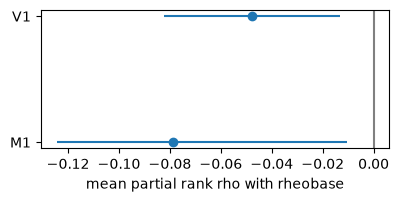

In [3]:
p = pd.read_csv(VALIDATION_TABLES / "primary_cohort_results.csv")
display(p[["cohort", "cells", "animals", "genes", "effect", "ci_lo", "ci_hi"]].round(4))
fig, ax = plt.subplots(figsize=(4.5, 1.8))
ax.errorbar(p["effect"], range(len(p)), xerr=[p["effect"] - p["ci_lo"], p["ci_hi"] - p["effect"]], fmt="o")
ax.axvline(0, color="grey"); ax.set_yticks(range(len(p)), p["cohort"].str.upper())
ax.set_xlabel("mean partial rank rho with rheobase"); plt.show()